# Préparation des Données — Inspection Industrielle VLM

Ce notebook couvre :
1. Téléchargement et organisation des datasets MVTec AD et NEU
2. Prétraitement et redimensionnement des images
3. Génération des templates d'annotations
4. Exploration et visualisation des données

In [6]:
import sys
sys.path.insert(0, '..')

import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from src.dataset import generate_annotation_template, DEFECT_LABELS

ModuleNotFoundError: No module named 'src.dataset'

## 1. Structure des répertoires

In [7]:
RAW_DIR = Path('../data/raw')
PROCESSED_DIR = Path('../data/processed')
TEMPLATES_DIR = Path('../data/templates')

for d in [RAW_DIR, PROCESSED_DIR, TEMPLATES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print('Répertoires créés :', [RAW_DIR, PROCESSED_DIR, TEMPLATES_DIR])

Répertoires créés : [WindowsPath('../data/raw'), WindowsPath('../data/processed'), WindowsPath('../data/templates')]


## 2. Prétraitement des images

In [8]:
TARGET_SIZE = (512, 512)

def preprocess_image(src: Path, dst: Path) -> None:
    img = Image.open(src).convert('RGB')
    img = img.resize(TARGET_SIZE, Image.LANCZOS)
    dst.parent.mkdir(parents=True, exist_ok=True)
    img.save(dst, quality=95)

processed_count = 0
for src_path in sorted(RAW_DIR.rglob('*.png')):
    relative = src_path.relative_to(RAW_DIR)
    dst_path = PROCESSED_DIR / relative
    preprocess_image(src_path, dst_path)
    processed_count += 1

print(f'{processed_count} images prétraitées → {PROCESSED_DIR}')

0 images prétraitées → ..\data\processed


## 3. Génération des annotations

In [ ]:
annotation_path = TEMPLATES_DIR / 'annotations.json'
generate_annotation_template(PROCESSED_DIR, annotation_path)

with open(annotation_path) as f:
    annotations = json.load(f)

print(f'Total annotations : {len(annotations)}')
print('\nExemple :')
print(json.dumps(annotations[0], ensure_ascii=False, indent=2))

## 4. Visualisation de la distribution des défauts

In [ ]:
from collections import Counter

label_counts = Counter(a['label'] for a in annotations)

fig, ax = plt.subplots(figsize=(10, 5))
labels, counts = zip(*sorted(label_counts.items(), key=lambda x: -x[1]))
bars = ax.bar(labels, counts, color='#2563eb', alpha=0.85, edgecolor='white')
ax.set_title('Distribution des types de défauts', fontsize=14, fontweight='bold')
ax.set_xlabel('Type de défaut')
ax.set_ylabel('Nombre d\'images')
ax.bar_label(bars)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('../data/templates/distribution_defauts.png', dpi=150)
plt.show()

## 5. Visualisation des exemples

In [ ]:
samples_per_class = 3
unique_labels = list(label_counts.keys())[:4]

fig, axes = plt.subplots(len(unique_labels), samples_per_class, figsize=(12, 4 * len(unique_labels)))
if len(unique_labels) == 1:
    axes = [axes]

for row_idx, label in enumerate(unique_labels):
    class_samples = [a for a in annotations if a['label'] == label][:samples_per_class]
    for col_idx, sample in enumerate(class_samples):
        img_path = Path('..') / sample['image_path']
        if img_path.exists():
            img = Image.open(img_path)
            axes[row_idx][col_idx].imshow(img)
            axes[row_idx][col_idx].set_title(f'{label} #{col_idx+1}', fontsize=10)
        axes[row_idx][col_idx].axis('off')

plt.suptitle('Exemples par type de défaut', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [1]:
from datasets import load_dataset

ds = load_dataset("foersben/mvtec-ad")

c:\Users\Dell\Desktop\industrial-vlm-inspection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


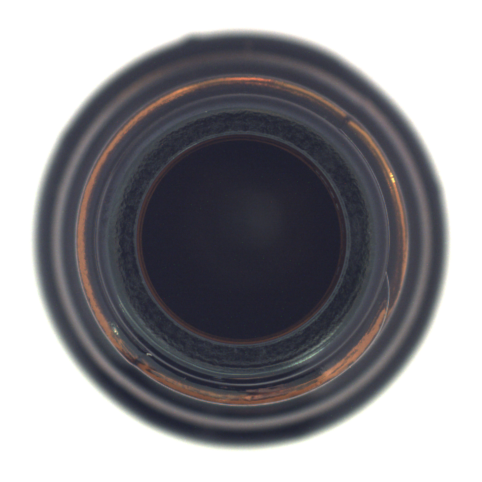

In [6]:
import matplotlib.pyplot as plt

example = ds["train"][0]

plt.figure(figsize=(6, 6))
plt.imshow(example["image"])
plt.axis("off")
plt.show()

In [ ]:
from pathlib import Path
from huggingface_hub import snapshot_download

# Racine du projet
PROJECT_DIR = Path.cwd()

# Dossier de destination
DATA_DIR = PROJECT_DIR / "data" / "mvtec-ad"
DATA_DIR.mkdir(parents=True, exist_ok=True)

path = snapshot_download(
    repo_id="foersben/mvtec-ad",
    repo_type="dataset",
    local_dir=str(DATA_DIR)
)

print(f"Dataset enregistré dans : {path}")

Fetching 14603 files:  38%|███▊      | 5588/14603 [05:40<26:08,  5.75it/s]  